# Réseau de neurones simple avec Keras

Dans cette démonstration, nous construisons avec Keras des réseaux de neurones qui reconnaissent les chiffres manuscrits de MNIST :

1. une régression logistique multinomiale, le réseau sans couche cachée ;
2. un perceptron multicouche régularisé ;
3. une recherche d'hyper-paramètres avec KerasTuner ;
4. le suivi de l'entraînement avec TensorBoard, l'arrêt précoce et la sauvegarde du meilleur modèle.

Il n'est pas nécessaire d'utiliser une carte graphique pour cette démonstration : chaque entraînement est rapide sur CPU, et seule la recherche d'hyper-paramètres prend quelques minutes. Vous pouvez donc changer d'environnement si celui qui vous a été attribué a une carte graphique (`Exécution > Modifier le type d'exécution`).

In [1]:
!pip install -q keras-tuner
import keras
import keras_tuner
import matplotlib.pyplot as plt
import numpy as np
from keras import layers

# Mêmes tirages aléatoires à chaque exécution : des résultats reproductibles
keras.utils.set_random_seed(0)

## Récupération des données

Cette fois, nous récupérons le jeu de données par Keras.

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

## Regardons les données

Commençons par la façon dont sont stockées les données : la forme et le type des quatre tableaux, la valeur des premières étiquettes, l'intervalle des pixels et le nombre d'exemples de chaque classe.

In [3]:
print(f"Format de X_train : {X_train.shape}, de X_test : {X_test.shape}")
print(f"Format de y_train : {y_train.shape}, de y_test : {y_test.shape}")
print(f"Type des images : {X_train.dtype}, de {X_train.min()} à {X_train.max()}")
print(f"Type des étiquettes : {y_train.dtype}, premières : {y_train[:10]}")
print(f"Exemples par classe : {np.bincount(y_train)}")

Format de X_train : (60000, 28, 28), de X_test : (10000, 28, 28)
Format de y_train : (60000,), de y_test : (10000,)
Type des images : uint8, de 0 à 255
Type des étiquettes : uint8, premières : [5 0 4 1 9 2 1 3 1 4]
Exemples par classe : [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


Nous avons 60 000 images d'entraînement et 10 000 de test, de 28 × 28 pixels : des entiers non signés sur 8 bits (`uint8`), de 0 à 255. Les étiquettes sont des entiers, de 0 à 9. Chaque classe compte de 5 421 à 6 742 exemples : les classes sont à peu près équilibrées.

Voici les dix premières images, avec leur étiquette.

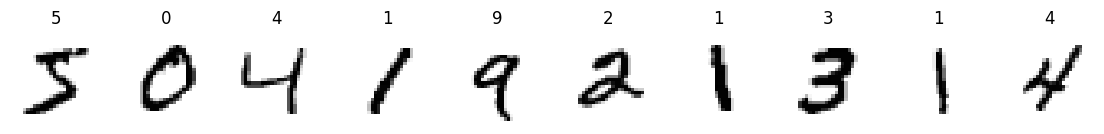

In [4]:
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for i, ax in enumerate(axes):
  ax.imshow(X_train[i], cmap="gray_r")
  ax.set_title(y_train[i])
  ax.axis("off")
plt.show()

## Transformation des données

Nous devons transformer ces données :

1. Aplatir les images : un tableau de forme `(_, 784)` plutôt que `(_, 28, 28)`, où `_` est le nombre d'exemples. Chaque image devient un vecteur de 784 pixels, l'entrée attendue par une couche `Dense`.
2. Ramener les pixels dans l'intervalle $[0, 1]$ plutôt que $[0, 255]$.
3. Encoder les classes en [*one-hot*](https://fr.wikipedia.org/wiki/Encodage_one-hot) : la première des deux pertes que nous verrons, `categorical_crossentropy`, attend pour chaque exemple 10 valeurs, toutes nulles sauf un 1 à l'indice de sa classe.

Nous gardons `y_train` et `y_test`, et rangeons les classes encodées dans `Y_train` et `Y_test`.

In [5]:
nb_classes = 10
dim_entree = 28 * 28

# Des images « à plat » : l'entrée du réseau est un vecteur de input_dim pixels,
# dans [0, 1]. -1 laisse NumPy calculer le nombre d'exemples.
X_train = X_train.reshape(-1, dim_entree) / 255
X_test = X_test.reshape(-1, dim_entree) / 255

# Les classes en vecteurs one-hot, pour categorical_crossentropy
Y_train = keras.utils.to_categorical(y_train, num_classes=nb_classes)
Y_test = keras.utils.to_categorical(y_test, num_classes=nb_classes)
print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)
print(f"Étiquette {y_train[0]} en one-hot : {Y_train[0]}")

(60000, 784) (10000, 784) (60000, 10) (10000, 10)
Étiquette 5 en one-hot : [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## Régression logistique multinomiale

Le premier modèle n'a pas de couche cachée : une entrée `keras.Input` de `dim_entree` pixels, puis une couche `layers.Dense` de `nb_classes` neurones, avec l'activation softmax. Chaque neurone calcule une combinaison linéaire des pixels, et la softmax en fait 10 probabilités de somme 1 : c'est une régression logistique multinomiale.

In [6]:
modele = keras.Sequential(
  [keras.Input(shape=(dim_entree,)), layers.Dense(nb_classes, activation="softmax")]
)
modele.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

Une couche `Dense` a un poids par entrée et par neurone, plus un biais par neurone : 784 × 10 + 10 = 7 850 paramètres. `None` est la taille du batch, libre.

## Apprentissage

Nous compilons le modèle avec `compile` : l'optimiseur `"sgd"` (descente de gradient stochastique, pas d'apprentissage de 0,01), la perte `categorical_crossentropy`, qui prend les cibles one-hot `Y_train`, et la métrique `"accuracy"`. Nous l'entraînons ensuite avec `fit`, avec :

- 128 exemples par batch ;
- 10 epochs ;
- 20 % des données d'entraînement en validation (`validation_split`).

Enfin, la fonction `evalue` mesure sa perte et son accuracy sur le jeu de test. Ces chiffres servent de référence aux modèles suivants.

In [7]:
def evalue(modele: keras.Model, one_hot: bool = False) -> None:
  """Affiche la perte et l'accuracy de `model` sur le jeu de test.

  one_hot : True pour un modèle entraîné sur les cibles one-hot (Y_train).
  """
  perte, justesse = modele.evaluate(X_test, Y_test if one_hot else y_test, verbose=0)
  print(f"Test : perte {perte:.3f}, accuracy {justesse:.3f}")

In [8]:
# compile associe au modèle un optimiseur, une fonction de perte et des métriques
modele.compile(optimizer="sgd", loss="categorical_crossentropy", metrics=["accuracy"])

# fit entraîne le modèle compilé : une boucle d'entraînement complète
historique = modele.fit(
  X_train, Y_train, batch_size=128, epochs=10, validation_split=0.2
)
evalue(modele, one_hot=True)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.6740 - loss: 1.3776 - val_accuracy: 0.8325 - val_loss: 0.8860
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8336 - loss: 0.7852 - val_accuracy: 0.8615 - val_loss: 0.6519
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8521 - loss: 0.6389 - val_accuracy: 0.8725 - val_loss: 0.5588
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8619 - loss: 0.5686 - val_accuracy: 0.8791 - val_loss: 0.5073
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8687 - loss: 0.5256 - val_accuracy: 0.8841 - val_loss: 0.4740
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8738 - loss: 0.4960 - val_accuracy: 0.8875 - val_loss: 0.4504
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8778 - loss: 0.4740 - val_accuracy: 0.8902 - val_loss: 0.4325
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8805 - loss: 0.4569 - val_accuracy: 0.

La régression logistique atteint 89,6 % d'accuracy en validation à la dernière epoch, et 89,5 % en test, pour une perte de test de 0,40.

## Une perte pour les étiquettes entières

La perte `sparse_categorical_crossentropy` calcule la même entropie croisée, mais à partir des étiquettes entières `y_train` : l'encodage one-hot devient inutile. Entraînons `modele2`, identique au précédent, avec cette perte et les mêmes réglages.

In [9]:
modele2 = keras.Sequential(
  [keras.Input(shape=(dim_entree,)), layers.Dense(nb_classes, activation="softmax")]
)
modele2.compile(
  optimizer="sgd", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
modele2.fit(X_train, y_train, batch_size=128, epochs=10, validation_split=0.2)
evalue(modele2)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6708 - loss: 1.3834 - val_accuracy: 0.8277 - val_loss: 0.8895
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8303 - loss: 0.7897 - val_accuracy: 0.8570 - val_loss: 0.6536
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8513 - loss: 0.6410 - val_accuracy: 0.8697 - val_loss: 0.5592
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8629 - loss: 0.5693 - val_accuracy: 0.8773 - val_loss: 0.5071
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8692 - loss: 0.5256 - val_accuracy: 0.8818 - val_loss: 0.4734
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8742 - loss: 0.4956 - val_accuracy: 0.8863 - val_loss: 0.4495
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8778 - loss: 0.4733 - val_accuracy: 0.8888 - val_loss: 0.4316
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8810 - loss: 0.4560 - val_accuracy: 0.

Les mêmes résultats, aux tirages aléatoires près (initialisation, ordre des batchs) : seul le format des cibles change. Les étiquettes entières évitent de stocker 10 valeurs par exemple.

## Perceptron multicouche régularisé

La fonction `construit_modele_profond` renvoie un perceptron multicouche neuf, non compilé :

- 4 couches cachées de 20 neurones, avec l'activation ReLU ;
- sur leurs poids, une pénalité L2 de coefficient $10^{-4}$ (`kernel_regularizer`) et l'initialisation de He (`kernel_initializer`), adaptée à ReLU ;
- la même couche de sortie softmax que la régression logistique.

Nous en créons un, `modele_profond`, compilé avec l'optimiseur `"adam"`, la perte `sparse_categorical_crossentropy` et l'accuracy, et entraîné avec les mêmes réglages que la régression logistique. Les parties suivantes réutilisent `construit_modele_profond`.

In [10]:
def construit_modele_profond() -> keras.Model:
  """Un perceptron multicouche neuf : 4 couches cachées régularisées de 20 neurones."""
  options_cachees = dict(
    activation="relu",
    kernel_regularizer=keras.regularizers.L2(1e-4),
    kernel_initializer="he_normal",
  )
  return keras.Sequential(
    [
      keras.Input(shape=(dim_entree,)),
      layers.Dense(20, **options_cachees),
      layers.Dense(20, **options_cachees),
      layers.Dense(20, **options_cachees),
      layers.Dense(20, **options_cachees),
      layers.Dense(nb_classes, activation="softmax"),
    ],
    name="modele_profond",
  )


modele_profond = construit_modele_profond()
modele_profond.summary()
modele_profond.compile(
  optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
modele_profond.fit(X_train, y_train, batch_size=128, epochs=10, validation_split=0.2)
evalue(modele_profond)

Model: "modele_profond"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 20)             │        15,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           210 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,170 (67.07 KB)

 Trainable params: 17,170 (67.07 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.7794 - loss: 0.7258 - val_accuracy: 0.9183 - val_loss: 0.3081
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9224 - loss: 0.2857 - val_accuracy: 0.9349 - val_loss: 0.2411
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9360 - loss: 0.2348 - val_accuracy: 0.9418 - val_loss: 0.2204
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9450 - loss: 0.2079 - val_accuracy: 0.9453 - val_loss: 0.2081
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9503 - loss: 0.1904 - val_accuracy: 0.9461 - val_loss: 0.2015
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9545 - loss: 0.1777 - val_accuracy: 0.9485 - val_loss: 0.1968
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9574 - loss: 0.1674 - val_accuracy: 0.9490 - val_loss: 0.1971
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9604 - loss: 0.1587 - val_accuracy: 0.

Environ 5 points de plus que la régression logistique (94,8 % contre 89,5 % en test), pour 17 170 paramètres au lieu de 7 850. Une partie du gain vient d'Adam : la partie TensorBoard compare les deux optimiseurs sur ce modèle.

## Recherche d'hyper-paramètres

Combien de neurones dans la couche cachée, quel pas d'apprentissage ? KerasTuner essaie des combinaisons d'hyper-paramètres et garde la meilleure, notée sur le jeu de validation.

La fonction `construit_modele(hp)` renvoie un perceptron à une couche cachée ReLU, compilé avec Adam, la perte `sparse_categorical_crossentropy` et l'accuracy. Elle lit ses hyper-paramètres dans `hp` :

- `unites`, le nombre de neurones cachés : de 32 à 512, par pas de 32 ;
- `taux_apprentissage`, le pas d'apprentissage d'Adam : de $10^{-4}$ à $10^{-2}$, en échelle logarithmique.

La recherche passe par `keras_tuner.BayesianOptimization` : objectif `val_accuracy`, 5 essais, chacun entraîné 3 fois pour une moyenne moins bruitée, 10 epochs par entraînement, des batchs de 1 500 exemples et 20 % de validation. C'est la partie la plus longue : quelques minutes sur CPU.

In [11]:
def construit_modele(hp: keras_tuner.HyperParameters) -> keras.Model:
  # Chaque appel de hp lit la valeur que le tuner a choisie pour l'essai en cours
  unites = hp.Int("unites", min_value=32, max_value=512, step=32)
  taux_apprentissage = hp.Float(
    "taux_apprentissage", min_value=1e-4, max_value=1e-2, sampling="log"
  )
  modele = keras.Sequential(
    [
      keras.Input(shape=(dim_entree,)),
      layers.Dense(unites, activation="relu"),
      layers.Dense(nb_classes, activation="softmax"),
    ]
  )
  modele.compile(
    optimizer=keras.optimizers.Adam(taux_apprentissage),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
  )
  return modele


tuner = keras_tuner.BayesianOptimization(
  construit_modele,
  objective="val_accuracy",
  max_trials=5,
  executions_per_trial=3,
  seed=0,
  directory="tuner",
  project_name="mnist",
  overwrite=True,
)
tuner.search_space_summary()

Search space summary
Default search space size: 2
unites (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
taux_apprentissage (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': None, 'sampling': 'log'}


In [12]:
tuner.search(X_train, y_train, epochs=10, batch_size=1500, validation_split=0.2)

Trial 5 Complete [00h 00m 20s]
val_accuracy: 0.9304999907811483

Best val_accuracy So Far: 0.9455833236376444
Total elapsed time: 00h 01m 43s


In [13]:
tuner.results_summary()
meilleur_modele = tuner.get_best_models()[0]
meilleur_modele.summary()
evalue(meilleur_modele)

Results summary
Results in tuner/mnist
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 0 summary
Hyperparameters:
unites: 352
taux_apprentissage: 0.0003076479630142435
Score: 0.9455833236376444

Trial 2 summary
Hyperparameters:
unites: 512
taux_apprentissage: 0.00020263128279152088
Score: 0.941361129283905

Trial 3 summary
Hyperparameters:
unites: 448
taux_apprentissage: 0.0001906261608057756
Score: 0.9375555515289307

Trial 4 summary
Hyperparameters:
unites: 128
taux_apprentissage: 0.0003187720102714487
Score: 0.9304999907811483

Trial 1 summary
Hyperparameters:
unites: 96
taux_apprentissage: 0.000254400127046171
Score: 0.9194166858990988


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 352)            │       276,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         3,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 279,850 (1.07 MB)

 Trainable params: 279,850 (1.07 MB)

 Non-trainable params: 0 (0.00 B)

Test : perte 0.206, accuracy 0.943


Le meilleur essai (352 neurones, un pas d'apprentissage de $3 \times 10^{-4}$) atteint 94,6 % en validation et 94,3 % en test, moins que `modele_profond` (94,8 %), avec 279 850 paramètres au lieu de 17 170. Avec 10 epochs et des batchs de 1 500 exemples, chaque entraînement ne fait que 320 pas.

À l'exécution, `get_best_models` prévient qu'il ne recharge pas l'état de l'optimiseur (`Skipping variable loading for optimizer`) : les poids du modèle sont bien là, et ils suffisent pour l'évaluer.

## Adam contre SGD sous TensorBoard

TensorBoard affiche les courbes d'apprentissage qu'un callback [`keras.callbacks.TensorBoard`](https://keras.io/api/callbacks/tensorboard/), passé à `fit`, écrit dans un dossier : un sous-dossier par entraînement.

Nous entraînons deux perceptrons multicouches neufs (`construit_modele_profond()`) avec les réglages de la partie « Perceptron multicouche régularisé », l'un avec l'optimiseur `"adam"`, l'autre avec `"sgd"`. Chaque `fit` reçoit un callback qui écrit dans `logs/adam` pour le premier, dans `logs/sgd` pour le second.

In [14]:
for optimiseur in ["adam", "sgd"]:
  modele = construit_modele_profond()
  modele.compile(
    optimizer=optimiseur, loss="sparse_categorical_crossentropy", metrics=["accuracy"]
  )
  tensorboard = keras.callbacks.TensorBoard(log_dir=f"logs/{optimiseur}")
  modele.fit(
    X_train,
    y_train,
    batch_size=128,
    epochs=10,
    validation_split=0.2,
    callbacks=[tensorboard],
  )

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7577 - loss: 0.7623 - val_accuracy: 0.9154 - val_loss: 0.3125
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9206 - loss: 0.2907 - val_accuracy: 0.9314 - val_loss: 0.2487
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9348 - loss: 0.2388 - val_accuracy: 0.9392 - val_loss: 0.2217
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9429 - loss: 0.2091 - val_accuracy: 0.9432 - val_loss: 0.2084
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9495 - loss: 0.1880 - val_accuracy: 0.9467 - val_loss: 0.2019
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9545 - loss: 0.1726 - val_accuracy: 0.9492 - val_loss: 0.1951
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9588 - loss: 0.1606 - val_accuracy: 0.9517 - val_loss: 0.1893
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9622 - loss: 0.1506 - val_accuracy: 0.

La cellule suivante ouvre le tableau de bord, qui ne s'affiche que dans une session en cours : il faut exécuter le notebook pour le voir.

In [15]:
%load_ext tensorboard
%tensorboard --logdir logs

<IPython.core.display.Javascript object>

Dans l'onglet *Scalars*, les courbes `epoch_loss` et `epoch_accuracy` superposent les deux entraînements ; `train` et `validation` séparent les courbes d'entraînement et de validation.

Elles montrent ce que disent les journaux de `fit` ci-dessus : Adam converge bien plus vite. Il dépasse 90 % d'accuracy en validation dès la première epoch (91,5 %) et finit à 95,6 %, quand SGD n'y arrive qu'à la cinquième et finit à 92,4 %. SGD multiplie le gradient de chaque poids par le même pas d'apprentissage (0,01) ; Adam adapte le pas de chaque poids à la taille de ses gradients récents, et garde une inertie d'un pas à l'autre (la moyenne des gradients).

## Arrêt précoce et sauvegarde du meilleur modèle

Plutôt que de fixer le nombre d'epochs à l'avance, on arrête l'entraînement quand la perte de validation ne baisse plus, et on garde le meilleur modèle vu.

Nous entraînons un perceptron multicouche neuf avec Adam, sur 50 epochs au plus, avec deux callbacks :

- `keras.callbacks.EarlyStopping` : arrêt après 3 epochs sans baisse de `val_loss`, et retour aux poids de la meilleure epoch ;
- `keras.callbacks.ModelCheckpoint` : sauvegarde du modèle dans `best.keras`, chaque fois que `val_loss` atteint un nouveau minimum.

Nous affichons le nombre d'epochs effectuées, puis comparons sur le test le modèle en mémoire et le modèle rechargé avec `keras.models.load_model`.

In [16]:
# Graine remise avant de tirer les poids : les cellules précédentes ne comptent plus
keras.utils.set_random_seed(0)
modele = construit_modele_profond()
modele.compile(
  optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
rappels = [
  # Arrêt après 3 epochs sans baisse de val_loss, poids de la meilleure epoch remis
  keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
  ),
  # Sauvegarde du modèle à chaque nouveau minimum de val_loss
  keras.callbacks.ModelCheckpoint(
    "meilleur.keras", monitor="val_loss", save_best_only=True
  ),
]
historique = modele.fit(
  X_train,
  y_train,
  batch_size=128,
  epochs=50,
  validation_split=0.2,
  callbacks=rappels,
)
print(f"Epochs effectuées : {len(historique.history['loss'])}")

evalue(modele)
meilleur_modele = keras.models.load_model("meilleur.keras")
evalue(meilleur_modele)

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.7685 - loss: 0.7334 - val_accuracy: 0.9172 - val_loss: 0.3085
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9246 - loss: 0.2793 - val_accuracy: 0.9379 - val_loss: 0.2338
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9400 - loss: 0.2253 - val_accuracy: 0.9438 - val_loss: 0.2139
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9469 - loss: 0.1983 - val_accuracy: 0.9458 - val_loss: 0.2044
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9525 - loss: 0.1798 - val_accuracy: 0.9463 - val_loss: 0.2003
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9565 - loss: 0.1663 - val_accuracy: 0.9479 - val_loss: 0.1991
Epoch 7/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9589 - loss: 0.1560 - val_accuracy: 0.9480 - val_loss: 0.1993
Epoch 8/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9614 - loss: 0.1483 - val_accuracy: 0.

L'entraînement s'arrête à l'epoch 12, 3 epochs après le minimum de `val_loss` (epoch 9). Le modèle en mémoire et le modèle rechargé donnent les mêmes chiffres : `restore_best_weights` remet dans le modèle les poids de la meilleure epoch, celle que `ModelCheckpoint` a sauvegardée en dernier. Sans lui, le modèle en mémoire garderait les poids de la dernière epoch, 3 epochs après la meilleure.